<a href="https://colab.research.google.com/github/andysuryandi/health-data-analysis-python/blob/main/notebooks/Suryandi_HealthDataExplorer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Health Explorer – Analyse von Gesundheitsdaten

## Einführung

In diesem Projekt analysiere ich einen Gesundheitsdatensatz mit 50.002 Einträgen. Ich untersuche BMI, geschätzten Körperfettanteil, Alter, Geschlecht, Aktivitätslevel und Raucherstatus.

Zunächst prüfe ich die Daten auf Vollständigkeit, identische Zeilen und konsistente Kategorien. Auffälligkeiten und Entscheidungen zur Datenbereinigung dokumentiere ich vor der Analyse.

Anschließend beantworte ich sieben vorgegebene und drei eigene Analysefragen. Für jede Frage erläutere ich das Vorgehen, berechne die Ergebnisse und interpretiere die passenden Visualisierungen.

Der Körperfettanteil wurde aus BMI, Alter und Geschlecht berechnet und nicht direkt gemessen. Die Ergebnisse beschreiben Zusammenhänge innerhalb dieses Datensatzes und erlauben keine Aussagen über Ursache und Wirkung.

Zum Abschluss fasse ich die wichtigsten Erkenntnisse zusammen und bespreche die Grenzen der Analyse.

## Setup

Ich lade die Bibliotheken für die Datenanalyse und Visualisierung und lege einen einheitlichen Diagrammstil fest.


In [1]:
# Standard imports for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# A consistent look across all your plots
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100

## Daten laden

Ich lade den Datensatz aus der CSV-Datei und prüfe anhand der ersten fünf Zeilen, ob die Daten korrekt eingelesen wurden.

In [2]:
import pandas as pd

# CSV direkt aus GitHub laden
url = (
    "https://raw.githubusercontent.com/"
    "andysuryandi/health-data-analysis-python/"
    "main/data/health_data_processed.csv"
)

df_raw = pd.read_csv(url)

# Arbeitskopie für die Analyse erstellen
df = df_raw.copy()

print("Zeilen und Spalten:", df.shape)
display(df.head())

Zeilen und Spalten: (50002, 11)


,Height,Weight,Gender,Age,Activity_Level,Smoker,BMI,bmi_category,BF%,message,bf_healthy
0,1.62,53.80,F,19,Sedentary,No,20.50,Normal weight,23.57,Great work – your BMI is in the healthy range!...,True
1,1.72,76.12,M,56,Lightly Active,No,25.73,Overweight,27.56,Your BMI is in the overweight range. Aim for g...,False
2,1.80,87.38,M,69,Sedentary,No,26.97,Overweight,32.03,Your BMI is in the overweight range. Aim for g...,False
3,1.80,74.28,M,20,Very Active,No,22.93,Normal weight,15.92,Great work – your BMI is in the healthy range!...,True
4,1.63,62.76,F,54,Lightly Active,No,23.62,Normal weight,35.36,Great work – your BMI is in the healthy range!...,False


## Prüfung der Datenqualität

Vor der Analyse prüfe ich die Daten auf fehlende Werte,
Duplikate, Datentypen und uneinheitliche Kategorien.


In [3]:
# Überblick: Zeilen, Spalten und Datentypen
print("Zeilen und Spalten:", df.shape)
df.info()

# Fehlende Werte je Spalte
print("\nFehlende Werte:")
print(df.isna().sum())

# Vollständig identische Zeilen
print("\nIdentische Zeilen:", df.duplicated().sum())

# Schreibweisen und Häufigkeiten der Aktivitätslevel
print("\nAktivitätslevel:")
print(df["Activity_Level"].value_counts(dropna=False))

Zeilen und Spalten: (50002, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50002 entries, 0 to 50001
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Height          50002 non-null  float64
 1   Weight          50002 non-null  float64
 2   Gender          50002 non-null  object 
 3   Age             50002 non-null  int64  
 4   Activity_Level  50002 non-null  object 
 5   Smoker          50002 non-null  object 
 6   BMI             50002 non-null  float64
 7   bmi_category    50002 non-null  object 
 8   BF%             50002 non-null  float64
 9   message         50002 non-null  object 
 10  bf_healthy      50002 non-null  bool   
dtypes: bool(1), float64(4), int64(1), object(5)
memory usage: 3.9+ MB

Fehlende Werte:
Height            0
Weight            0
Gender            0
Age               0
Activity_Level    0
Smoker            0
BMI               0
bmi_category      0
BF%               0
messag

### Ergebnis

Der Datensatz enthält 50.002 Zeilen und 11 Spalten.
Es wurden keine fehlenden Werte gefunden.
Es gibt 96 zusätzliche vollständig identische Zeilen.
In der Spalte `Activity_Level` kommt die Kategorie `Moderate`
einmal vor, zusätzlich zu `Moderately Active`.

### Interpretation

Die identischen Zeilen und die abweichende Kategorie werden
genauer untersucht. Ohne eindeutige Personen-ID lässt sich
nicht sicher feststellen, ob identische Zeilen doppelte
Personeneinträge sind. Außerdem ist zu klären, ob `Moderate`
dieselbe Bedeutung wie `Moderately Active` hat.
Eine Bereinigung erfolgt erst nach dieser Prüfung.

### Prüfung auffälliger Einträge

Ich untersuche vollständig identische Zeilen und den Eintrag
mit dem Aktivitätslevel `Moderate`, bevor ich über Änderungen entscheide.

In [4]:
# Alle Exemplare vollständig identischer Zeilen anzeigen
display(df.loc[df.duplicated(keep=False)])

# Eintrag mit der abweichenden Kategorie anzeigen
display(df.loc[df["Activity_Level"] == "Moderate"])

,Height,Weight,Gender,Age,Activity_Level,Smoker,BMI,bmi_category,BF%,message,bf_healthy
746,1.63,61.20,F,52,Moderately Active,No,23.03,Normal weight,34.20,Great work – your BMI is in the healthy range!...,False
1534,1.58,45.00,F,19,Lightly Active,No,18.03,Underweight,20.61,Your BMI suggests you are underweight. Conside...,True
1569,1.67,75.23,M,69,Lightly Active,No,26.97,Overweight,32.03,Your BMI is in the overweight range. Aim for g...,False
1698,1.70,68.31,M,46,Lightly Active,No,23.64,Normal weight,22.75,Great work – your BMI is in the healthy range!...,False
2064,1.45,45.00,F,44,Lightly Active,No,21.40,Normal weight,30.40,Great work – your BMI is in the healthy range!...,True
...,...,...,...,...,...,...,...,...,...,...,...
49389,1.55,49.77,F,34,Sedentary,No,20.72,Normal weight,27.28,Great work – your BMI is in the healthy range!...,True
49501,1.45,45.00,F,25,Lightly Active,No,21.40,Normal weight,26.03,Great work – your BMI is in the healthy range!...,True
49875,1.46,45.00,F,35,Sedentary,No,21.11,Normal weight,27.98,Great work – your BMI is in the healthy range!...,True
49952,1.70,70.29,F,79,Sedentary,No,24.32,Normal weight,41.95,Great work – your BMI is in the healthy range!...,False


,Height,Weight,Gender,Age,Activity_Level,Smoker,BMI,bmi_category,BF%,message,bf_healthy
50001,1.65,83.0,F,54,Moderate,No,30.49,Obese,43.61,Your BMI falls in the obese range. Consulting ...,False


In [5]:
# Zusätzliche identische Zeilen
print("Zusätzliche identische Zeilen:", df.duplicated().sum())

# Alle beteiligten Zeilen einschließlich der ersten Exemplare
print("Alle beteiligten Zeilen:", df.duplicated(keep=False).sum())

Zusätzliche identische Zeilen: 96
Alle beteiligten Zeilen: 188


### Ergebnis

Es wurden 96 zusätzliche vollständig identische Zeilen gefunden.
Insgesamt gehören 188 Zeilen zu Gruppen mit identischen Werten.

Die Kategorie `Moderate` kommt einmal in der Spalte
`Activity_Level` vor.

### Interpretation

Ohne eindeutige Personen-ID lässt sich nicht sicher feststellen,
ob identische Zeilen doppelte Erfassungen oder unterschiedliche
Personen mit gleichen Merkmalen sind. Sie werden deshalb beibehalten.

Für `Moderate` ist nicht eindeutig belegt, ob die Kategorie
`Moderately Active` gemeint ist. Der Wert bleibt vorerst unverändert.

### Prüfung der numerischen Wertebereiche

Ich untersuche die Verteilung von Alter, Körpergröße,
Gewicht, BMI und geschätztem Körperfettanteil.
Minimum, Maximum und Quartile geben einen ersten Überblick
über die Wertebereiche und mögliche Auffälligkeiten.

In [6]:
# Wertebereiche prüfen und auf zwei Nachkommastellen runden
display(df[["Age", "Height", "Weight", "BMI", "BF%"]].describe().round(2))

,Age,Height,Weight,BMI,BF%
count,50002.00,50002.00,50002.00,50002.00,50002.00
mean,49.07,1.69,67.35,23.50,28.43
std,18.21,0.10,11.21,2.28,7.43
min,18.00,1.45,45.00,15.84,8.69
25%,33.00,1.62,59.08,21.93,22.93
50%,49.00,1.68,66.57,23.44,28.41
75%,65.00,1.76,75.02,25.00,33.65
max,80.00,2.00,111.33,34.46,51.03


### Ergebnis

Für Alter, Körpergröße, Gewicht, BMI und Körperfettanteil wurden
Anzahl, Mittelwert, Standardabweichung, Quartile sowie Minimum
und Maximum berechnet. Alle fünf Spalten enthalten 50.002 Werte.

### Interpretation

Die Übersicht dient als erste Prüfung der Wertebereiche.
Minimum und Maximum helfen, auffällige Einträge zu erkennen.
Ob die Angaben untereinander konsistent sind, muss zusätzlich
geprüft werden, beispielsweise durch einen Vergleich des
gespeicherten BMI mit dem aus Gewicht und Größe berechneten BMI.

### Prüfung der Kategorien für Geschlecht und Raucherstatus

Ich prüfe, welche Werte vorkommen und ob unterschiedliche
Schreibweisen oder unerwartete Kategorien vorhanden sind.

In [7]:
# Kategorien und ihre Häufigkeiten anzeigen
for spalte in ["Gender", "Smoker"]:
    print(f"\n{spalte}:")
    print(df[spalte].value_counts(dropna=False))


Gender:
Gender
M    26194
F    23808
Name: count, dtype: int64

Smoker:
Smoker
No     43641
Yes     6361
Name: count, dtype: int64


### Ergebnis

Die Spalte `Gender` enthält ausschließlich die Kategorien
`M` und `F`. In der Spalte `Smoker` kommen ausschließlich
`Yes` und `No` vor.

### Interpretation

Die Kategorien sind innerhalb der beiden Spalten einheitlich.
Eine Vereinheitlichung der Schreibweisen ist nicht erforderlich.
Die Prüfung bestätigt jedoch nicht die inhaltliche Richtigkeit
der Angaben.

### Prüfung grundlegender Wertebedingungen

Ich prüfe, ob Alter, Körpergröße oder Gewicht null oder negativ
sind und ob der Körperfettanteil außerhalb von 0 bis 100 liegt.
Diese Prüfung ersetzt keine vollständige Plausibilitätsprüfung.

In [8]:
# Grundlegende ungültige Werte zählen
pruefung = pd.Series({
    "Alter kleiner oder gleich 0": (df["Age"] <= 0).sum(),
    "Körpergröße kleiner oder gleich 0": (df["Height"] <= 0).sum(),
    "Gewicht kleiner oder gleich 0": (df["Weight"] <= 0).sum(),
    "Körperfettanteil außerhalb 0–100": (
        (df["BF%"] < 0) | (df["BF%"] > 100)
    ).sum()
})

display(pruefung.to_frame(name="Anzahl"))

,Anzahl
Alter kleiner oder gleich 0,0
Körpergröße kleiner oder gleich 0,0
Gewicht kleiner oder gleich 0,0
Körperfettanteil außerhalb 0–100,0


### Ergebnis

Alter, Körpergröße und Gewicht enthalten keine Werte kleiner
oder gleich null. Kein Körperfettanteil liegt außerhalb des
Bereichs von 0 bis 100.

### Interpretation

Die Daten erfüllen die geprüften grundlegenden Wertebedingungen.
Das bestätigt jedoch nicht, dass alle Angaben realistisch oder
inhaltlich korrekt sind.


### Prüfung der Kategorien von bf_healthy

Ich prüfe, welche Werte in der Spalte `bf_healthy` vorkommen
und wie häufig sie sind.

In [9]:
display(df["bf_healthy"].value_counts(dropna=False))

,count
bf_healthy,
False,30509
True,19493


### Ergebnis

Die Spalte `bf_healthy` enthält ausschließlich die Werte
`False` (30.509 Einträge) und `True` (19.493 Einträge).
Es gibt keine fehlenden Werte.

### Interpretation

Die Spalte enthält die erwarteten booleschen Werte.
Ob die Zuordnung korrekt nach den vorgesehenen Regeln
berechnet wurde, ist durch diese Häufigkeitsprüfung
noch nicht bestätigt.

### Prüfung der Vollständigkeit der Aktivitätskategorien

Ich prüfe, ob alle Zeilen bei der Zählung der Aktivitätskategorien
berücksichtigt werden, einschließlich der Kategorie `Moderate`.

In [10]:
# Häufigkeiten einschließlich aller vorhandenen Aktivitätskategorien
display(
    df["Activity_Level"]
    .value_counts(dropna=False)
    .to_frame(name="Anzahl")
)

# Kontrollieren, ob alle Zeilen erfasst sind
print("Erfasste Zeilen:", df["Activity_Level"].value_counts(dropna=False).sum())
print("Zeilen im Datensatz:", len(df))

,Anzahl
Activity_Level,
Lightly Active,17596
Sedentary,16956
Moderately Active,11621
Very Active,3828
Moderate,1


Erfasste Zeilen: 50002
Zeilen im Datensatz: 50002


### Ergebnis

Die Häufigkeitszählung erfasst alle 50.002 Zeilen.
Die Kategorie `Moderate` ist mit einem Eintrag enthalten.

### Interpretation

Bei dieser Zählung werden keine Zeilen ausgeschlossen.
In späteren Tabellen und Diagrammen muss zusätzlich darauf
geachtet werden, dass auch `Moderate` berücksichtigt wird.

### Umgang mit der Kategorie „Moderate“

Da die Bedeutung von `Moderate` nicht eindeutig geklärt ist,
bleibt die Kategorie unverändert. Bei Gruppenvergleichen wird
sie mit n=1 gekennzeichnet. Ein einzelner Eintrag erlaubt keine
allgemeinen Aussagen über diese Aktivitätsgruppe.

### Prüfung der Alterswerte

Ich prüfe, ob die Alterswerte numerisch und ganzzahlig sind
und innerhalb des geprüften Bereichs von 18 bis 80 Jahren liegen.
Die ursprünglichen Werte bleiben unverändert.

In [11]:
# Alterswerte vorübergehend in numerische Werte umwandeln
age_check = pd.to_numeric(df["Age"], errors="coerce")

# Auffälligkeiten getrennt prüfen
age_issues = pd.DataFrame({
    "Fehlend": df["Age"].isna(),
    "Nicht numerisch": df["Age"].notna() & age_check.isna(),
    "Nicht ganzzahlig": age_check.notna() & age_check.mod(1).ne(0),
    "Außerhalb 18–80": (
        age_check.notna() & ~age_check.between(18, 80)
    )
})

display(age_issues.sum().rename("Anzahl").to_frame())

# Betroffene Datensätze anzeigen
invalid_age = age_issues.any(axis=1)
print("Datensätze mit Altersauffälligkeiten:", invalid_age.sum())

if invalid_age.any():
    display(df.loc[invalid_age])

,Anzahl
Fehlend,0
Nicht numerisch,0
Nicht ganzzahlig,0
Außerhalb 18–80,0


Datensätze mit Altersauffälligkeiten: 0


### Ergebnis der Altersprüfung

Alle Alterswerte sind vorhanden, numerisch und ganzzahlig.
Sie liegen innerhalb des geprüften Bereichs von 18 bis 80 Jahren.
Eine Bereinigung der Alterswerte ist daher nicht erforderlich.

Die Prüfung bestätigt die formale Plausibilität. Ob jedes Alter
tatsächlich korrekt erfasst wurde, lässt sich damit nicht feststellen.

### Prüfung der Textspalten auf Leerzeichen

Ich prüfe alle Textspalten auf führende und nachgestellte Leerzeichen,
mehrfache oder abweichende innere Leerzeichen sowie leere Texte.
Die Originalwerte bleiben unverändert.

In [12]:
# Alle Textspalten auswählen
text_columns = df.select_dtypes(include=["object", "string"]).columns

text_checks = []

for column in text_columns:
    values = df[column].astype("string")
    stripped = values.str.strip()
    normalized_spaces = stripped.str.replace(r"\s+", " ", regex=True)

    text_checks.append({
        "Spalte": column,
        "Äußere Leerzeichen": (
            values.ne(stripped).fillna(False).sum()
        ),
        "Auffällige innere Leerzeichen": (
            stripped.ne(normalized_spaces).fillna(False).sum()
        ),
        "Leere Texte nach Trimmen": (
            stripped.eq("").fillna(False).sum()
        )
    })

display(pd.DataFrame(text_checks))

,Spalte,Äußere Leerzeichen,Auffällige innere Leerzeichen,Leere Texte nach Trimmen
0,Gender,0,0,0
1,Activity_Level,0,0,0
2,Smoker,0,0,0
3,bmi_category,0,0,0
4,message,0,0,0


### Ergebnis der Leerzeichenprüfung

In den fünf Textspalten wurden keine führenden oder nachgestellten
Leerzeichen, keine auffälligen inneren Leerzeichen und keine leeren
Texte nach dem Trimmen gefunden. Eine Bereinigung ist nicht erforderlich.

### Prüfung der Groß-/Kleinschreibung

Ich prüfe, ob innerhalb einer Textspalte unterschiedliche Schreibweisen
desselben Wertes vorkommen, die sich nur durch Groß-/Kleinschreibung
unterscheiden. Die Originalwerte bleiben unverändert.

In [13]:
# Schreibvarianten innerhalb jeder Textspalte suchen
capitalization_found = False

for column in text_columns:
    unique_values = df[column].dropna().astype("string").drop_duplicates()

    variants = pd.DataFrame({
        "Originalwert": unique_values,
        "Prüfschlüssel": unique_values.str.casefold()
    })

    # Mehrere Originalwerte mit gleichem Prüfschlüssel markieren
    inconsistent = variants[
        variants["Prüfschlüssel"].duplicated(keep=False)
    ].sort_values(["Prüfschlüssel", "Originalwert"])

    if not inconsistent.empty:
        capitalization_found = True
        print(f"Schreibvarianten in {column}:")
        display(inconsistent)

if not capitalization_found:
    print("Keine uneinheitliche Groß-/Kleinschreibung gefunden.")

Keine uneinheitliche Groß-/Kleinschreibung gefunden.


### Ergebnis der Prüfung der Groß-/Kleinschreibung

In keiner der fünf Textspalten wurden unterschiedliche Werte gefunden,
die sich ausschließlich durch Groß-/Kleinschreibung unterscheiden.
Eine Vereinheitlichung ist daher nicht erforderlich.

## Validierung der berechneten Merkmale

Ich prüfe die gespeicherten BMI-Werte, BMI-Kategorien,
geschätzten Körperfettanteile und Körperfettstatuswerte
anhand der bereitgestellten Funktionen. Die ursprünglichen
Werte bleiben dabei erhalten.

In [14]:
# BMI anhand der vorgegebenen Grenzwerte kategorisieren
def categorize_bmi(bmi):
    if bmi < 18.5:
        return "Underweight"
    elif bmi < 25:
        return "Normal weight"
    elif bmi < 30:
        return "Overweight"
    else:
        return "Obese"

In [15]:
# BMI-Kategorien mit der bereitgestellten Funktion neu bestimmen
bmi_category_check = df["BMI"].apply(categorize_bmi)

# Abweichungen von den gespeicherten Kategorien markieren
bmi_category_mismatch = bmi_category_check != df["bmi_category"]

# Anzahl der Abweichungen anzeigen
print("Abweichende BMI-Kategorien:", bmi_category_mismatch.sum())

# Betroffene Zeilen anzeigen, falls Abweichungen vorhanden sind
if bmi_category_mismatch.any():
    display(df.loc[bmi_category_mismatch, ["BMI", "bmi_category"]])

Abweichende BMI-Kategorien: 0


### Ergebnis der BMI-Kategorienprüfung

Die gespeicherten BMI-Kategorien stimmen in allen Zeilen mit der bereitgestellten Funktion `categorize_bmi()` überein. Eine Korrektur der Kategorien ist daher nicht erforderlich.

### Hilfsfunktionen für die Validierung und Analyse

Die folgenden Funktionen berechnen den BMI und den geschätzten
Körperfettanteil. Die Funktion `healthy_bf()` prüft anhand der
vorgegebenen alters- und geschlechtsspezifischen Referenzbereiche,
ob der Körperfettanteil innerhalb dieser Grenzen liegt.

In [16]:
def calculate_bmi(weight_kg, height_m):
    """BMI = weight in kg divided by height in metres squared."""
    return weight_kg / (height_m ** 2)

def calculate_body_fat(bmi, age, gender):
    """Body fat % using the Deurenberg formula. Gender is 'M' or 'F'."""
    gender_factor = 1 if gender == 'M' else 0
    return 1.20 * bmi + 0.23 * age - 10.8 * gender_factor - 5.4


# Healthy BF% ranges by age bracket and gender
# Each entry is (lower_bound, upper_bound), both inclusive
healthy_bf_ranges = {
    '18-29': {'M': (9, 20),    'F': (19, 28)},
    '30-39': {'M': (11, 21),   'F': (21.5, 29)},
    '40-49': {'M': (13, 22),   'F': (24, 31)},
    '50-59': {'M': (16, 24),   'F': (25, 33)},
    '60+':   {'M': (19, 25),   'F': (28, 35)},
}


def healthy_bf(row):
    """Returns True if the person's BF% falls in the healthy range for
    their age bracket and gender. Expects a row with Age, Gender, BF%."""

    age = row['Age']

    if age <= 29:
        bracket = '18-29'
    elif age <= 39:
        bracket = '30-39'
    elif age <= 49:
        bracket = '40-49'
    elif age <= 59:
        bracket = '50-59'
    else:
        bracket = '60+'

    lo, hi = healthy_bf_ranges[bracket][row['Gender']]

    return lo <= row['BF%'] <= hi

### Prüfung des Körperfettstatus

Ich berechne den Körperfettstatus mit der Funktion `healthy_bf()`
neu und vergleiche ihn mit der gespeicherten Spalte `bf_healthy`.
Abweichende Zuordnungen werden gezählt und gegenübergestellt.
Die ursprüngliche Spalte bleibt unverändert.

In [17]:
# Körperfettstatus mit der bereitgestellten Funktion neu bestimmen
bf_healthy_check = df.apply(healthy_bf, axis=1)

# Abweichungen vom gespeicherten Status markieren
bf_healthy_mismatch = bf_healthy_check != df["bf_healthy"]

# Anzahl der Abweichungen anzeigen
print("Abweichender Körperfettstatus:", bf_healthy_mismatch.sum())

# Gespeicherten und neu berechneten Status gegenüberstellen
bf_comparison = df.loc[
    bf_healthy_mismatch,
    ["Age", "Gender", "BMI", "BF%", "bf_healthy"]
].copy()

bf_comparison["bf_healthy_check"] = bf_healthy_check.loc[
    bf_healthy_mismatch
]

display(bf_comparison)

Abweichender Körperfettstatus: 11


,Age,Gender,BMI,BF%,bf_healthy,bf_healthy_check
5075,18,M,17.78,9.28,False,True
7773,21,M,16.98,9.01,False,True
9893,19,M,18.08,9.87,False,True
14505,20,M,17.81,9.77,False,True
29320,18,M,18.06,9.61,False,True
30497,19,F,16.33,18.57,True,False
32396,19,M,17.99,9.76,False,True
39842,18,M,17.80,9.30,False,True
42925,18,M,18.28,9.88,False,True
49160,18,M,17.98,9.52,False,True


### Ergebnis der Körperfettstatusprüfung

Bei elf Datensätzen stimmt die gespeicherte Spalte `bf_healthy` nicht mit dem Ergebnis der bereitgestellten Funktion `healthy_bf()` überein.

Bei zehn Männern ergibt die Funktion `True`, während `False` gespeichert ist. Bei einer Frau ergibt die Funktion `False`, während `True` gespeichert ist. Die Ursache dieser Abweichungen ist nicht geklärt.

Ich behalte die ursprüngliche Spalte unverändert und dokumentiere die Unterschiede. Für die Analysefragen verwende ich jeweils die ausdrücklich geforderte Spalte beziehungsweise Funktion.

### Prüfung der BMI-Berechnung

Ich berechne den BMI aus Gewicht und Körpergröße mit der
Funktion `calculate_bmi()` neu und vergleiche ihn mit den
gespeicherten BMI-Werten. Dabei berücksichtige ich eine
Rundungstoleranz von 0,005 BMI-Punkten.
Die ursprünglichen Werte bleiben unverändert.

In [18]:
# BMI aus Gewicht und Körpergröße neu berechnen
bmi_check = df.apply(
    lambda row: calculate_bmi(row["Weight"], row["Height"]),
    axis=1
)

# Absolute Differenz zum gespeicherten BMI berechnen
bmi_difference = (bmi_check - df["BMI"]).abs()

# Rundung auf zwei Nachkommastellen berücksichtigen
bmi_mismatch = bmi_difference > 0.005 + 1e-9

# Prüfergebnisse anzeigen
print("Größte absolute BMI-Differenz:", round(bmi_difference.max(), 6))
print("Abweichungen außerhalb der Rundungstoleranz:", bmi_mismatch.sum())

# Auffällige Zeilen mit neu berechnetem BMI anzeigen
if bmi_mismatch.any():
    bmi_comparison = df.loc[
        bmi_mismatch, ["Height", "Weight", "BMI"]
    ].copy()

    bmi_comparison["BMI_check"] = bmi_check.loc[bmi_mismatch]
    bmi_comparison["Absolute_difference"] = bmi_difference.loc[bmi_mismatch]

    display(bmi_comparison)

Größte absolute BMI-Differenz: 0.005
Abweichungen außerhalb der Rundungstoleranz: 0


### Ergebnis der BMI-Berechnungsprüfung

Die aus Gewicht und Körpergröße neu berechneten BMI-Werte stimmen innerhalb der Rundungstoleranz mit den gespeicherten Werten überein.

Die größte absolute Differenz beträgt 0,005. Es gibt keine Abweichungen außerhalb der Toleranz für zwei Nachkommastellen. Eine Korrektur der gespeicherten BMI-Werte ist daher nicht erforderlich.

### Prüfung der Körperfettberechnung

Ich berechne den geschätzten Körperfettanteil mit der Funktion
`calculate_body_fat()` aus BMI, Alter und Geschlecht neu.
Anschließend vergleiche ich ihn mit den gespeicherten BF%-Werten.

Unter Berücksichtigung der Rundung von BMI und Körperfettanteil
verwende ich eine Toleranz von 0,011 Prozentpunkten.
Die ursprünglichen Werte bleiben unverändert.

In [19]:
# Körperfettanteil mit der bereitgestellten Formel neu berechnen
bf_check = df.apply(
    lambda row: calculate_body_fat(
        row["BMI"], row["Age"], row["Gender"]
    ),
    axis=1
)

# Absolute Differenz zum gespeicherten Körperfettanteil berechnen
bf_difference = (bf_check - df["BF%"]).abs()

# Rundung von BMI und Körperfettwert berücksichtigen
bf_tolerance = 1.20 * 0.005 + 0.005
bf_mismatch = bf_difference > bf_tolerance + 1e-9

# Prüfergebnisse anzeigen
print("Größte absolute BF%-Differenz:", round(bf_difference.max(), 6))
print("Rundungstoleranz:", round(bf_tolerance, 6))
print("Abweichungen außerhalb der Toleranz:", bf_mismatch.sum())

# Auffällige Zeilen mit neu berechnetem Wert anzeigen
if bf_mismatch.any():
    bf_value_comparison = df.loc[
        bf_mismatch, ["BMI", "Age", "Gender", "BF%"]
    ].copy()

    bf_value_comparison["BF%_check"] = bf_check.loc[bf_mismatch]
    bf_value_comparison["Absolute_difference"] = (
        bf_difference.loc[bf_mismatch]
    )

    display(bf_value_comparison)

Größte absolute BF%-Differenz: 0.016
Rundungstoleranz: 0.011
Abweichungen außerhalb der Toleranz: 4


,BMI,Age,Gender,BF%,BF%_check,Absolute_difference
1132,22.22,63,M,24.97,24.954,0.016
6378,22.04,37,M,18.77,18.758,0.012
11260,27.58,66,M,32.06,32.076,0.016
49792,23.08,20,M,16.11,16.096,0.014


### Ergebnis der Körperfett-Berechnungsprüfung

Bei vier Datensätzen überschreitet die Differenz zwischen gespeichertem und neu berechnetem Körperfettanteil die festgelegte Rundungstoleranz von 0,011 Prozentpunkten. Die größte absolute Differenz beträgt 0,016 Prozentpunkte.

Die Ursache ist nicht geklärt. Ich behalte die gespeicherten Werte bei und dokumentiere die geringfügigen Abweichungen als Konsistenzbefund.

## Umgang mit Datenauffälligkeiten

Die Datenprüfung ergab keine fehlenden Werte und keine
Verstöße gegen die geprüften grundlegenden Wertebedingungen.
Die wichtigsten Befunde und die daraus abgeleiteten
Entscheidungen sind nachfolgend zusammengefasst.

| Befund | Entscheidung |
|---|---|
| Alterswerte vollständig, numerisch, ganzzahlig und im geprüften Bereich 18–80 Jahre | Keine Korrektur aufgrund dieser Prüfung |
| Keine auffälligen Leerzeichen, leeren Texte oder Varianten nur durch Groß-/Kleinschreibung | Keine Vereinheitlichung erforderlich |
| 96 zusätzliche vollständig identische Zeilen | Beibehalten, da doppelte Erfassungen ohne Personen-ID nicht nachgewiesen sind |
| `Moderate` mit einem Eintrag | Unverändert lassen und bei Gruppenvergleichen mit n=1 kennzeichnen |
| BMI-Werte innerhalb der Rundungstoleranz; BMI-Kategorien konsistent | Originalwerte beibehalten |
| Vier Körperfettwerte außerhalb der angenommenen Rundungstoleranz | Originalwerte beibehalten und Abweichungen dokumentieren |
| Elf Abweichungen zwischen `bf_healthy` und `healthy_bf()` | Originalspalte beibehalten; verwendete Spalte oder Funktion bei der jeweiligen Analyse ausdrücklich nennen |

### Zusammenfassung der Datenprüfung

Der Datensatz enthält 50.002 Zeilen und 11 Spalten.
Es wurden keine fehlenden Werte gefunden.

Die Alterswerte sind numerisch, ganzzahlig und liegen im
geprüften Bereich von 18 bis 80 Jahren. Die grundlegenden
Wertebedingungen sowie die Prüfungen auf Leerzeichen und
abweichende Groß-/Kleinschreibung zeigen keine Auffälligkeiten.

Die gespeicherten BMI-Werte stimmen innerhalb der verwendeten
Rundungstoleranz mit der Neuberechnung überein. Alle
BMI-Kategorien entsprechen der verwendeten Funktion.

Beim geschätzten Körperfettanteil liegen vier Abweichungen
außerhalb der angenommenen Rundungstoleranz von 0,011
Prozentpunkten. Die größte Differenz beträgt 0,016 Prozentpunkte.

Bei elf Einträgen weicht der gespeicherte Körperfettstatus
vom Ergebnis der Funktion `healthy_bf()` ab. Die Ursachen
sind nicht geklärt; die Originalwerte bleiben erhalten.

96 zusätzliche vollständig identische Zeilen werden beibehalten,
da ohne Personen-ID keine doppelte Erfassung nachgewiesen
werden kann. Die einmal vorkommende Kategorie `Moderate`
bleibt unverändert und wird bei Gruppenvergleichen mit n=1
gekennzeichnet.

Es wurden keine Datenwerte verändert. Die Ausgangsdaten
bleiben in `df_raw` erhalten. Die Prüfungen bestätigen nicht
die vollständige inhaltliche Richtigkeit der Daten.

# Teil 1 — Vorgegebene Fragen

In diesem Teil beantworte ich sieben vorgegebene Fragen.

Bei jeder Frage erkläre ich kurz, was ich untersuche. Danach führe ich die Analyse mit Python durch, visualisiere die Ergebnisse und schreibe eine kurze Interpretation.

---
---

### Question 1 — BMI Category Distribution by Gender

Provide the total counts and percentages of males and females across BMI categories. Note any differences between genders, and visualize the results using Seaborn as you best see fit.

### Vorgehen

Ich untersuche, wie sich die BMI-Kategorien zwischen Frauen und Männern unterscheiden.

Dafür berechne ich zuerst die Anzahl und danach den prozentualen Anteil für jede BMI-Kategorie. Anschließend stelle ich die Ergebnisse in einem Diagramm dar.

In [20]:
# Fachliche Reihenfolge der BMI-Kategorien festlegen
bmi_order = [
    "Underweight",
    "Normal weight",
    "Overweight",
    "Obese"]

# Anzahl je BMI-Kategorie und Geschlecht berechnen
bmi_counts = pd.crosstab(
    df["bmi_category"],
    df["Gender"]
).reindex(index=bmi_order, columns=["F", "M"], fill_value=0)

# Prozentanteile innerhalb jedes Geschlechts berechnen
bmi_percentages = bmi_counts.div(
    bmi_counts.sum(axis=0), axis=1
).mul(100)

# Ergebnisse mit lesbaren Spaltennamen anzeigen
print("Anzahl je BMI-Kategorie:")
display(bmi_counts.rename(columns={"F": "Frauen", "M": "Männer"}))

print("Anteil innerhalb des jeweiligen Geschlechts (%):")
display(
    bmi_percentages
    .rename(columns={"F": "Frauen", "M": "Männer"})
    .round(2)
)

Anzahl je BMI-Kategorie:


Gender,Frauen,Männer
bmi_category,,
Underweight,321,137
Normal weight,19690,17332
Overweight,3779,8573
Obese,18,152


Anteil innerhalb des jeweiligen Geschlechts (%):


Gender,Frauen,Männer
bmi_category,,
Underweight,1.35,0.52
Normal weight,82.70,66.17
Overweight,15.87,32.73
Obese,0.08,0.58


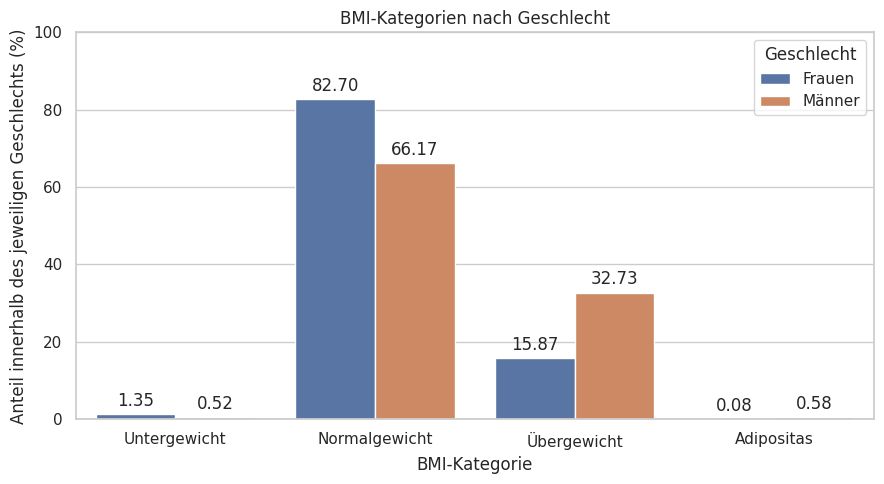

In [21]:
# Prozentwerte für das Diagramm ins lange Format umwandeln
bmi_plot = bmi_percentages.reset_index().melt(
    id_vars="bmi_category",
    var_name="Gender",
    value_name="Percentage"
)

# Lesbare Beschriftungen für das Diagramm erstellen
bmi_plot["Geschlecht"] = bmi_plot["Gender"].map({
    "F": "Frauen",
    "M": "Männer"
})

bmi_labels = {
    "Underweight": "Untergewicht",
    "Normal weight": "Normalgewicht",
    "Overweight": "Übergewicht",
    "Obese": "Adipositas"
}

bmi_plot["BMI-Kategorie"] = bmi_plot["bmi_category"].map(bmi_labels)

# Prozentanteile innerhalb jedes Geschlechts visualisieren
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=bmi_plot,
    x="BMI-Kategorie",
    y="Percentage",
    hue="Geschlecht",
    order=[bmi_labels[category] for category in bmi_order],
    hue_order=["Frauen", "Männer"]
)

# Prozentwerte über den Balken anzeigen
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("BMI-Kategorien nach Geschlecht")
plt.xlabel("BMI-Kategorie")
plt.ylabel("Anteil innerhalb des jeweiligen Geschlechts (%)")
plt.ylim(0, 100)
plt.legend(title="Geschlecht")
plt.tight_layout()
plt.show()

### Interpretation

Normalgewicht ist bei beiden Geschlechtern die häufigste BMI-Kategorie. Der Anteil beträgt bei Frauen 82,70 % und bei Männern 66,17 %.

Der größte Unterschied zeigt sich beim Übergewicht: 32,73 % der Männer und 15,87 % der Frauen fallen in diese Kategorie. Der Anteil liegt bei Männern damit um 16,86 Prozentpunkte höher.

Untergewicht und Adipositas kommen vergleichsweise selten vor. Untergewicht ist bei Frauen häufiger, Adipositas bei Männern.

Die Ergebnisse beschreiben die Verteilung innerhalb des vorliegenden Datensatzes. Ursachen für die Unterschiede lassen sich aus diesem Vergleich nicht ableiten.

---
---

### Question 2 — Average Body Fat Percentage by Activity Level

Group the data by `Activity_Level` and compute the mean `BF%` for each group. Which activity level is associated with the lowest average body fat? Does the result surprise you?

Visualize the results using Seaborn as you best see fit.

### Vorgehen

Ich berechne den durchschnittlichen geschätzten Körperfettanteil, den Median und die Anzahl der Datensätze je Aktivitätslevel.

Anschließend vergleiche und visualisiere ich die Mittelwerte. Die ungeklärte Kategorie „Moderate“ kennzeichne ich gesondert, da sie nur einen Datensatz enthält.

In [22]:
# Reihenfolge der Aktivitätslevel festlegen
activity_order = [
    "Sedentary",
    "Lightly Active",
    "Moderately Active",
    "Very Active",
    "Moderate"]

# Gruppengröße, Mittelwert und Median des Körperfettanteils berechnen
activity_summary = (
    df.groupby("Activity_Level")["BF%"]
    .agg(
        Count="size",
        Mean_BF="mean",
        Median_BF="median")
    .reindex(activity_order))

# Ergebnisse anzeigen
display(
    activity_summary.rename(columns={
        "Count": "Anzahl",
        "Mean_BF": "Mittlerer geschätzter BF% (%)",
        "Median_BF": "Median des geschätzten BF% (%)"
    }).round(2))

,Anzahl,Mittlerer geschätzter BF% (%),Median des geschätzten BF% (%)
Activity_Level,,,
Sedentary,16956,29.60,29.57
Lightly Active,17596,28.54,28.54
Moderately Active,11621,27.20,27.16
Very Active,3828,26.51,26.43
Moderate,1,43.61,43.61


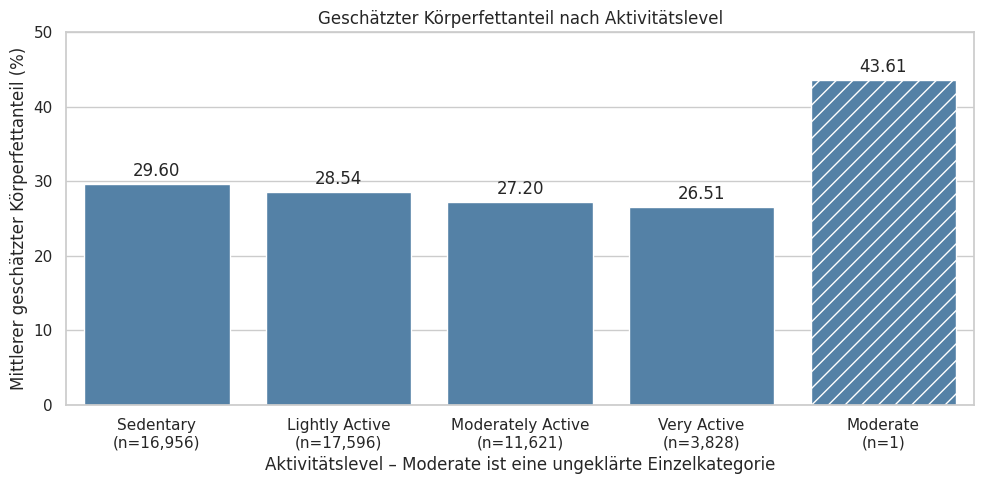

In [23]:
# Zusammenfassung für das Diagramm vorbereiten
activity_plot = activity_summary.reset_index()

# Mittelwerte nach Aktivitätslevel darstellen
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=activity_plot,
    x="Activity_Level",
    y="Mean_BF",
    order=activity_order,
    color="steelblue"
)

# Mittelwerte über den Balken anzeigen
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

# Gruppengrößen direkt an den Kategorien angeben
activity_tick_labels = [
    f"{level}\n(n={int(activity_summary.loc[level, 'Count']):,})"
    for level in activity_order
]

ax.set_xticks(range(len(activity_order)))
ax.set_xticklabels(activity_tick_labels)
ax.patches[-1].set_hatch("//")

plt.title("Geschätzter Körperfettanteil nach Aktivitätslevel")
plt.xlabel("Aktivitätslevel – Moderate ist eine ungeklärte Einzelkategorie")
plt.ylabel("Mittlerer geschätzter Körperfettanteil (%)")
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

### Interpretation

„Very Active“ hat mit 26,51 % den niedrigsten durchschnittlichen geschätzten Körperfettanteil. Danach folgen „Moderately Active“ mit 27,20 %, „Lightly Active“ mit 28,54 % und „Sedentary“ mit 29,60 %.

Auch die Medianwerte zeigen dasselbe Muster: Sie sinken von 29,57 % bei „Sedentary“ auf 26,43 % bei „Very Active“. Mittelwert und Median liegen in allen vier regulären Aktivitätsgruppen nahe beieinander.

Diese Richtung entspricht meiner Erwartung. Der Vergleich belegt jedoch nicht, dass Aktivität den Unterschied verursacht. Die Gruppen können sich auch hinsichtlich Alter, Geschlecht und BMI unterscheiden – den Merkmalen, aus denen der Körperfettanteil berechnet wird.

Die Kategorie „Moderate“ weist mit 43,61 % den höchsten Wert auf, enthält jedoch nur einen Datensatz. Ihr Mittelwert beschreibt daher ausschließlich diese einzelne Person und lässt keine allgemeine Aussage über eine Aktivitätsgruppe zu.

---
---

### Question 3 — Smokers vs Non-Smokers: who has healthier body fat?

Using the `bf_healthy` column, calculate the percentage of people with healthy BF% separately for smokers and non-smokers. What does the data suggest about the relationship between smoking and body fat health?

### Vorgehen

Ich vergleiche den Anteil der Datensätze mit Körperfett im vorgegebenen Referenzbereich zwischen Rauchern und Nichtrauchern.

Dafür verwende ich entsprechend der Aufgabenstellung die gespeicherte Spalte `bf_healthy`. Die zuvor festgestellten elf Abweichungen zur Funktion `healthy_bf()` bleiben als Einschränkung dokumentiert. Zusätzlich zeige ich die Gruppengrößen.

In [24]:
# Gruppengröße und Anzahl innerhalb des Referenzbereichs berechnen
smoking_summary = (
    df.groupby("Smoker")["bf_healthy"]
    .agg(
        Count="size",
        Within_Range="sum",
        Proportion="mean"
    )
    .reindex(["No", "Yes"]))

# Anteil in Prozent umrechnen
smoking_summary["Percentage"] = smoking_summary["Proportion"] * 100

# Ergebnisse mit lesbaren Beschriftungen anzeigen
display(
    smoking_summary[["Count", "Within_Range", "Percentage"]]
    .rename(
        index={"No": "Nichtraucher", "Yes": "Raucher"},
        columns={
            "Count": "Anzahl",
            "Within_Range": "Anzahl im Referenzbereich",
            "Percentage": "Anteil im Referenzbereich (%)"
        }
    )
    .round(2))

,Anzahl,Anzahl im Referenzbereich,Anteil im Referenzbereich (%)
Smoker,,,
Nichtraucher,43641,16933,38.80
Raucher,6361,2560,40.25


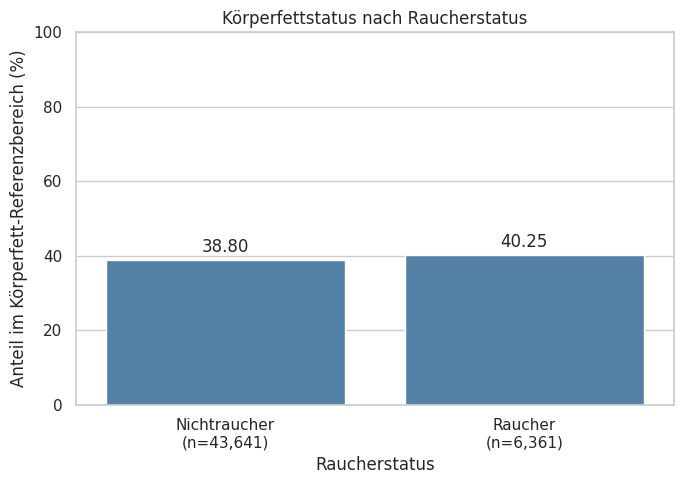

In [25]:
# Zusammenfassung für das Diagramm vorbereiten
smoking_plot = smoking_summary.reset_index()

# Prozentanteile nach Raucherstatus darstellen
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=smoking_plot,
    x="Smoker",
    y="Percentage",
    order=["No", "Yes"],
    color="steelblue"
)

# Prozentwerte über den Balken anzeigen
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

# Gruppen verständlich beschriften und Gruppengrößen ergänzen
ax.set_xticks([0, 1])
ax.set_xticklabels([
    f"Nichtraucher\n(n={int(smoking_summary.loc['No', 'Count']):,})",
    f"Raucher\n(n={int(smoking_summary.loc['Yes', 'Count']):,})"
])

plt.title("Körperfettstatus nach Raucherstatus")
plt.xlabel("Raucherstatus")
plt.ylabel("Anteil im Körperfett-Referenzbereich (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Interpretation

Laut der gespeicherten Spalte bf_healthy liegen 40,25 % der Raucher und 38,80 % der Nichtraucher im vorgegebenen Körperfett-Referenzbereich. Die Differenz aus den ungerundeten Anteilen beträgt rund 1,44 Prozentpunkte.

Raucher weisen in diesem Datensatz somit einen geringfügig höheren Anteil auf. Daraus lässt sich keine ursächliche Wirkung des Rauchens ableiten. Unterschiede in Alter, Geschlecht und BMI zwischen den Gruppen könnten das Ergebnis beeinflussen.

Der Vergleich verwendet entsprechend der Aufgabenstellung die vorhandene Spalte `bf_healthy`. Die elf zuvor dokumentierten Abweichungen zur bereitgestellten Prüffunktion bleiben dabei bestehen.

---
---

### Question 4 — BMI distribution among people over 45

Filter the dataset to only include people older than 45. Apply your `categorize_bmi()` function to confirm their BMI categories, and visualize the distribution of raw BMI values. How does this group compare to the full dataset?

**Tip:** you can use `plt.subplots(1, 2)` to place two plots side by side.

### Vorgehen

Ich filtere die Datensätze von Personen, die älter als 45 Jahre sind, und überprüfe ihre BMI-Kategorien mit der Funktion `categorize_bmi()`.

Anschließend vergleiche ich ihre BMI-Verteilung und ihren durchschnittlichen BMI mit dem gesamten Datensatz. Für die Histogramme verwende ich identische Klassengrenzen und Achsenskalen sowie Prozentanteile, damit die unterschiedlich großen Gruppen vergleichbar sind.

In [26]:
# Datensätze von Personen über 45 Jahren auswählen
over_45 = df.loc[df["Age"] > 45].copy()

# BMI-Kategorien mit der bereitgestellten Funktion überprüfen
over_45["BMI_Category_Check"] = (
    over_45["BMI"].apply(categorize_bmi)
)

# Abweichungen von den gespeicherten Kategorien zählen
category_mismatch = (
    over_45["BMI_Category_Check"] != over_45["bmi_category"]
)

print("Datensätze von Personen über 45:", len(over_45))
print("Abweichende BMI-Kategorien:", category_mismatch.sum())

# Gruppengrößen und durchschnittlichen BMI vergleichen
bmi_age_summary = pd.DataFrame({
    "Gruppe": ["Gesamter Datensatz", "Alter über 45"],
    "Anzahl": [len(df), len(over_45)],
    "Mittlerer BMI": [df["BMI"].mean(), over_45["BMI"].mean()]
})

display(bmi_age_summary.round(2))

Datensätze von Personen über 45: 27845
Abweichende BMI-Kategorien: 0


,Gruppe,Anzahl,Mittlerer BMI
0,Gesamter Datensatz,50002,23.50
1,Alter über 45,27845,24.16


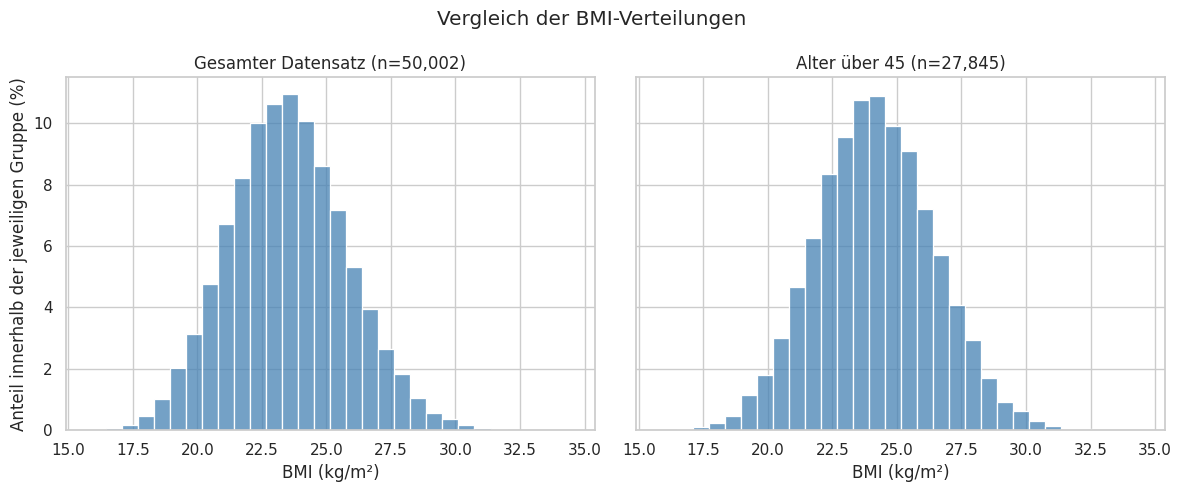

In [27]:
# Daten für die Visualisierung vorbereiten
bmi_bins = np.linspace(df["BMI"].min(), df["BMI"].max(), 31)

# Zwei Diagramme mit gemeinsamen Achsenskalen erstellen
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True)

# BMI-Verteilung des gesamten Datensatzes darstellen
sns.histplot(
    data=df,
    x="BMI",
    bins=bmi_bins,
    stat="percent",
    color="steelblue",
    ax=axes[0])

# BMI-Verteilung der Personen über 45 Jahre darstellen
sns.histplot(
    data=over_45,
    x="BMI",
    bins=bmi_bins,
    stat="percent",
    color="steelblue",
    ax=axes[1])

# Titel und Achsen beschriften
axes[0].set_title(f"Gesamter Datensatz (n={len(df):,})")
axes[1].set_title(f"Alter über 45 (n={len(over_45):,})")

for ax in axes:
    ax.set_xlabel("BMI (kg/m²)")
    ax.set_ylabel("Anteil innerhalb der jeweiligen Gruppe (%)")

fig.suptitle("Vergleich der BMI-Verteilungen")
plt.tight_layout()
plt.show()

### Interpretation

Die BMI-Verteilungen haben eine ähnliche Form. Bei Personen über 45 Jahren liegt die Verteilung jedoch etwas weiter im höheren BMI-Bereich.

Der durchschnittliche BMI beträgt im gesamten Datensatz 23,50 und in der Gruppe über 45 Jahre 24,16. Die Differenz beträgt ≈ 0,65 BMI-Punkte. Alle überprüften BMI-Kategorien dieser Altersgruppe stimmen mit der bereitgestellten Funktion überein.

Die Gruppe über 45 Jahre ist Teil des gesamten Datensatzes. Der Vergleich beschreibt daher eine Teilgruppe gegenüber der Gesamtgruppe und keine zwei unabhängigen Gruppen. Eine ursächliche Wirkung des Alters lässt sich daraus nicht ableiten.

---
---

### Question 5 — Gender × Smoking: a combined view

Compute the mean BMI and mean body fat percentage for each combination of gender and smoking status. Which combination has the highest average body fat percentage, and which has the lowest average BMI?

Use `.groupby()` — no individual calculations.

Visualize your result as a Seaborn `barplot` of mean BF% with gender on the x-axis and smoking status as the `hue`.

### Vorgehen

Ich gruppiere die Daten nach Geschlecht und Raucherstatus. Für jede der vier Gruppen berechne ich die Anzahl der Datensätze, den durchschnittlichen BMI und den durchschnittlichen geschätzten Körperfettanteil.

Anschließend ermittle ich die Gruppe mit dem höchsten mittleren Körperfettanteil und die Gruppe mit dem niedrigsten mittleren BMI. Den Körperfettanteil stelle ich in einem Balkendiagramm dar.

In [28]:
# Gruppengrößen und Mittelwerte nach Geschlecht und Raucherstatus berechnen
gender_smoking_summary = (
    df.groupby(["Gender", "Smoker"])
    .agg(
        Count=("BMI", "size"),
        Mean_BMI=("BMI", "mean"),
        Mean_BF=("BF%", "mean"))
    .reindex(
        pd.MultiIndex.from_product(
            [["F", "M"], ["No", "Yes"]],
            names=["Gender", "Smoker"]
        )))

# Ergebnisse mit lesbaren Beschriftungen anzeigen
display(
    gender_smoking_summary
    .rename(
        index={
            "F": "Frauen",
            "M": "Männer",
            "No": "Nichtraucher",
            "Yes": "Raucher"
        },
        columns={
            "Count": "Anzahl",
            "Mean_BMI": "Mittlerer BMI",
            "Mean_BF": "Mittlerer geschätzter BF% (%)"
        })
    .round(2))

Anzahl  Mittlerer BMI  Mittlerer geschätzter BF% (%)
Gender Smoker                                                            
Frauen Nichtraucher   21332          22.87                          33.37
       Raucher         2476          22.78                          33.17
Männer Nichtraucher   22309          24.10                          24.00
       Raucher         3885          23.99                          23.73

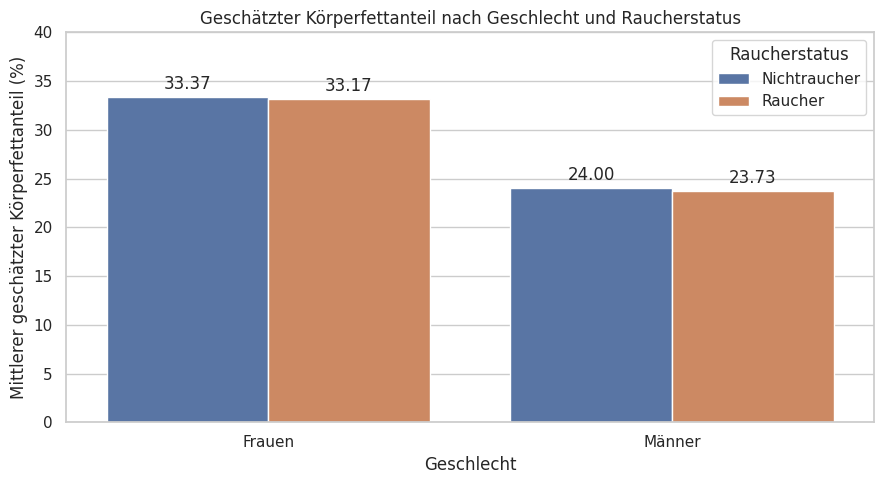

In [29]:
# Daten für die Visualisierung vorbereiten
gender_smoking_plot = gender_smoking_summary.reset_index()

gender_smoking_plot["Geschlecht"] = (
    gender_smoking_plot["Gender"].map({
        "F": "Frauen",
        "M": "Männer"
    })
)

gender_smoking_plot["Raucherstatus"] = (
    gender_smoking_plot["Smoker"].map({
        "No": "Nichtraucher",
        "Yes": "Raucher"
    })
)

# Mittleren geschätzten Körperfettanteil darstellen
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=gender_smoking_plot,
    x="Geschlecht",
    y="Mean_BF",
    hue="Raucherstatus",
    order=["Frauen", "Männer"],
    hue_order=["Nichtraucher", "Raucher"]
)

# Mittelwerte über den Balken anzeigen
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Geschätzter Körperfettanteil nach Geschlecht und Raucherstatus")
plt.xlabel("Geschlecht")
plt.ylabel("Mittlerer geschätzter Körperfettanteil (%)")
plt.ylim(0, 40)
plt.legend(title="Raucherstatus")
plt.tight_layout()
plt.show()

### Interpretation

Nichtraucherinnen haben mit 33,37 % den höchsten durchschnittlichen geschätzten Körperfettanteil. Der niedrigste durchschnittliche BMI liegt bei Raucherinnen und beträgt 22,78.

Innerhalb beider Geschlechter weisen Raucher etwas niedrigere mittlere Körperfettwerte auf als Nichtraucher. Die Unterschiede sind mit rund 0,20 Prozentpunkten bei Frauen und ≈ 0,28 Prozentpunkten bei Männern gering (24,003866 − 23,727310).

Der Unterschied zwischen Frauen und Männern fällt deutlich größer aus. Dabei ist zu berücksichtigen, dass das Geschlecht direkt in die Formel zur Körperfettschätzung eingeht. Dieser Vergleich ist daher keine unabhängige Bestätigung eines Geschlechterunterschieds.

Die Ergebnisse beschreiben Gruppenunterschiede im vorliegenden Datensatz. Eine ursächliche Wirkung des Rauchens lässt sich daraus nicht ableiten.

---
---

### Question 6 — Sedentary people and body fat health

Filter the dataset to sedentary individuals only. Use `.apply()` to run your `healthy_bf()` function row by row on this group, and report the percentage with healthy body fat broken down by gender.

Are sedentary males or females more likely to be in a healthy BF% range?

**Visualization:** a Seaborn `countplot` showing healthy vs unhealthy BF% counts, split by gender using `hue`.

### Vorgehen

Ich filtere die Datensätze mit dem Aktivitätslevel „Sedentary“. Anschließend berechne ich den Körperfettstatus mit `healthy_bf()` und `.apply(axis=1)` neu, wie in der Aufgabe verlangt.

Für Frauen und Männer ermittle ich jeweils die Gruppengröße und den Anteil innerhalb des vorgegebenen Referenzbereichs. Anschließend stelle ich die Anzahlen innerhalb und außerhalb dieses Bereichs mit einem Seaborn-Countplot dar.

In [30]:
# Datensätze mit dem Aktivitätslevel Sedentary auswählen
sedentary = df.loc[df["Activity_Level"] == "Sedentary"].copy()

# Körperfettstatus mit der bereitgestellten Funktion berechnen
sedentary["Healthy_BF_Check"] = sedentary.apply(
    healthy_bf, axis=1
)

# Gruppengrößen und Anteile nach Geschlecht berechnen
sedentary_summary = (
    sedentary.groupby("Gender")["Healthy_BF_Check"]
    .agg(
        Count="size",
        Within_Range="sum",
        Proportion="mean"
    )
    .reindex(["F", "M"])
)

# Anteile in Prozent umrechnen
sedentary_summary["Percentage"] = (
    sedentary_summary["Proportion"] * 100
)

# Ergebnisse mit lesbaren Beschriftungen anzeigen
print("Datensätze mit Aktivitätslevel Sedentary:", len(sedentary))

display(
    sedentary_summary[["Count", "Within_Range", "Percentage"]]
    .rename(
        index={"F": "Frauen", "M": "Männer"},
        columns={
            "Count": "Anzahl",
            "Within_Range": "Anzahl im Referenzbereich",
            "Percentage": "Anteil im Referenzbereich (%)"
        }
    )
    .round(2)
)

Datensätze mit Aktivitätslevel Sedentary: 16956


,Anzahl,Anzahl im Referenzbereich,Anteil im Referenzbereich (%)
Gender,,,
Frauen,8171,2495,30.53
Männer,8785,3084,35.11


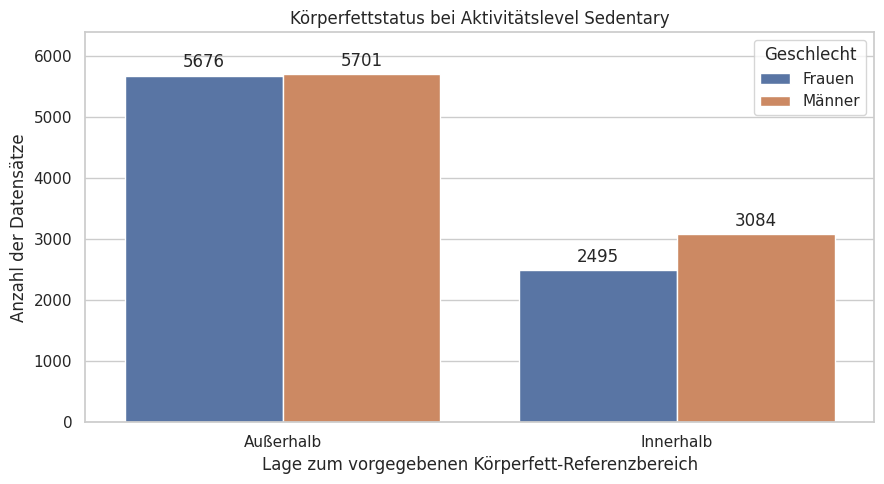

In [31]:
# Daten für die Visualisierung vorbereiten
sedentary_plot = sedentary.copy()

sedentary_plot["Geschlecht"] = sedentary_plot["Gender"].map({
    "F": "Frauen",
    "M": "Männer"
})

sedentary_plot["Körperfettstatus"] = (
    sedentary_plot["Healthy_BF_Check"].map({
        False: "Außerhalb",
        True: "Innerhalb"
    })
)

# Anzahlen nach Körperfettstatus und Geschlecht darstellen
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=sedentary_plot,
    x="Körperfettstatus",
    hue="Geschlecht",
    order=["Außerhalb", "Innerhalb"],
    hue_order=["Frauen", "Männer"]
)

# Anzahlen über den Balken anzeigen
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Körperfettstatus bei Aktivitätslevel Sedentary")
plt.xlabel("Lage zum vorgegebenen Körperfett-Referenzbereich")
plt.ylabel("Anzahl der Datensätze")
plt.legend(title="Geschlecht")
plt.margins(y=0.12)
plt.tight_layout()
plt.show()

### Interpretation

Bei den Datensätzen mit Aktivitätslevel „Sedentary“ liegen 35,11 % der Männer und 30,53 % der Frauen im vorgegebenen Körperfett-Referenzbereich. Der Anteil ist bei Männern damit um rund 4,57 Prozentpunkte höher.

Das entspricht 3.084 von 8.785 Männern und 2.495 von 8.171 Frauen. Bei beiden Geschlechtern liegt die Mehrheit außerhalb des Referenzbereichs.

Da die Gruppengrößen unterschiedlich sind, stützt sich der Vergleich auf die Prozentanteile und nicht allein auf die Balkenhöhen des Countplots.

Der Körperfettstatus wurde entsprechend der Aufgabenstellung mit `healthy_bf()` neu berechnet. Die Schätzung und die Referenzbereiche berücksichtigen Alter und Geschlecht. Der Unterschied erlaubt daher keine pauschale Aussage darüber, welches Geschlecht insgesamt gesünder ist.

---
---

### Question 7 — Health metrics across age groups

The `healthy_bf_ranges` dictionary defines five age brackets: 18–29, 30–39, 40–49, 50–59, and 60+. Using boolean indexing, filter the dataset into these five groups and for each one compute:

- Mean BMI
- Mean BF%
- Proportion of people with healthy BF%

Assemble the results into a summary DataFrame and display it. How do health metrics evolve as people age?

**Visualization:** a Seaborn `lineplot` with age group on the x-axis showing both mean BMI and mean BF% as two separate lines.

### Vorgehen

Ich teile den Datensatz mit Boolean Indexing in die fünf vorgegebenen Altersgruppen ein.

Für jede Gruppe berechne ich die Anzahl der Datensätze, den mittleren BMI, den mittleren geschätzten Körperfettanteil und den Anteil im Körperfett-Referenzbereich. Für diesen Anteil verwende ich die vorhandene Spalte `bf_healthy`.

Anschließend stelle ich die beiden Mittelwerte als separate Linien dar. BMI und Körperfettanteil haben unterschiedliche Einheiten; ihre Werte und Steigungen sind deshalb nicht direkt vergleichbar.

In [32]:
# Altersgruppen mit Boolean Indexing auswählen
age_groups = {
    "18-29": df.loc[(df["Age"] >= 18) & (df["Age"] <= 29)],
    "30-39": df.loc[(df["Age"] >= 30) & (df["Age"] <= 39)],
    "40-49": df.loc[(df["Age"] >= 40) & (df["Age"] <= 49)],
    "50-59": df.loc[(df["Age"] >= 50) & (df["Age"] <= 59)],
    "60+": df.loc[df["Age"] >= 60]
}

# Kennzahlen für jede Altersgruppe zusammenfassen
age_summary = pd.DataFrame([
    {
        "Age_Group": label,
        "Count": len(group),
        "Mean_BMI": group["BMI"].mean(),
        "Mean_BF": group["BF%"].mean(),
        "Percentage": group["bf_healthy"].mean() * 100
    }
    for label, group in age_groups.items()
])

# Prüfen, ob die Gruppen den gesamten Datensatz abdecken
print("Datensätze in den Altersgruppen:", age_summary["Count"].sum())
print("Datensätze insgesamt:", len(df))

# Ergebnisse mit lesbaren Beschriftungen anzeigen
display(
    age_summary.rename(columns={
        "Age_Group": "Altersgruppe",
        "Count": "Anzahl",
        "Mean_BMI": "Mittlerer BMI",
        "Mean_BF": "Mittlerer geschätzter BF% (%)",
        "Percentage": "Anteil im Referenzbereich (%)"
    }).round(2)
)


Datensätze in den Altersgruppen: 50002
Datensätze insgesamt: 50002


,Altersgruppe,Anzahl,Mittlerer BMI,Mittlerer geschätzter BF% (%),Anteil im Referenzbereich (%)
0,18-29,9524,22.65,21.48,81.54
1,30-39,7859,22.65,23.91,62.54
2,40-49,7957,22.94,26.78,43.33
3,50-59,7931,23.54,29.80,28.96
4,60+,16731,24.64,34.66,6.38


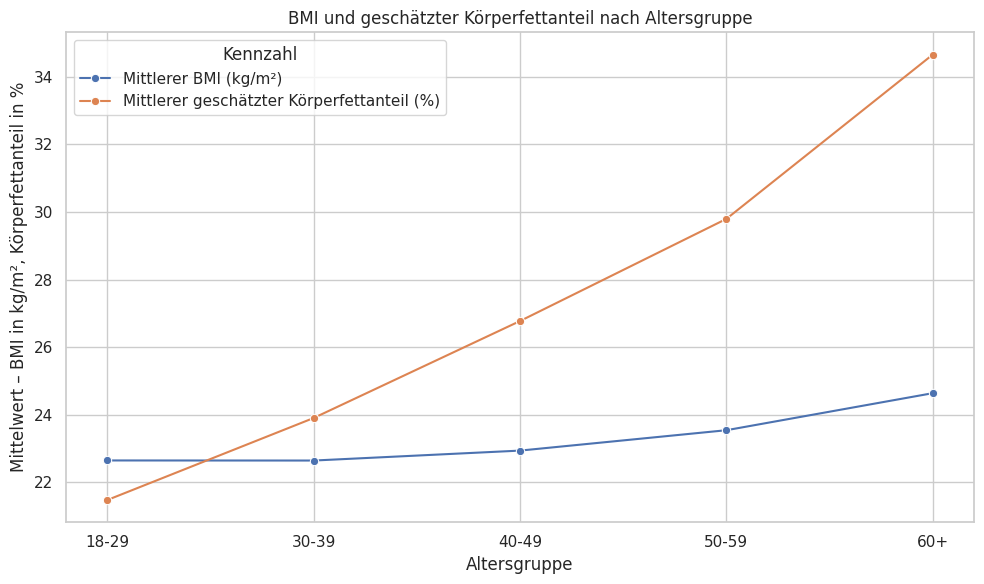

In [33]:
# Daten für die Visualisierung vorbereiten
age_plot = age_summary.copy()

# Beide Mittelwerte als separate Linien darstellen
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=age_plot,
    x="Age_Group",
    y="Mean_BMI",
    marker="o",
    label="Mittlerer BMI (kg/m²)",
    sort=False
)

sns.lineplot(
    data=age_plot,
    x="Age_Group",
    y="Mean_BF",
    marker="o",
    label="Mittlerer geschätzter Körperfettanteil (%)",
    sort=False,
    ax=ax
)

plt.title("BMI und geschätzter Körperfettanteil nach Altersgruppe")
plt.xlabel("Altersgruppe")
plt.ylabel("Mittelwert – BMI in kg/m², Körperfettanteil in %")
plt.legend(title="Kennzahl")
plt.tight_layout()
plt.show()

### Interpretation

Der mittlere BMI liegt in den beiden jüngsten Altersgruppen gerundet bei 22,65 und steigt anschließend bis auf 24,64 in der Gruppe ab 60 Jahren.

Der mittlere geschätzte Körperfettanteil nimmt über die Altersgruppen hinweg von 21,48 % auf 34,66 % zu. Gleichzeitig sinkt der Anteil im vorgegebenen Körperfett-Referenzbereich von 81,54 % auf 6,38 %.

Der Anstieg des geschätzten Körperfettanteils ist teilweise durch die Berechnungsformel vorgegeben, da das Alter direkt in die Schätzung eingeht. Auch die Referenzbereiche unterscheiden sich nach Alter und Geschlecht.

Die Ergebnisse vergleichen unterschiedliche Altersgruppen zu einem Zeitpunkt. Sie zeigen nicht, wie sich dieselben Personen im Laufe ihres Lebens verändern. Wegen der unterschiedlichen Einheiten sind die Steigungen der BMI- und Körperfettlinien nicht direkt vergleichbar.

---
---
## Teil 2 — Eigene Fragen

Nach den sieben vorgegebenen Fragen untersuche ich nun drei eigene Fragen.

Damit möchte ich weitere Zusammenhänge im Datensatz entdecken und verschiedene Merkmale miteinander vergleichen.

---
---

### My Question 1


Do people who receive the “healthy BMI” message also have a healthy body fat percentage, and does this differ between men and women?

**Columns:** message, bmi_category, bf_healthy, Gender

**Constraint:** Text-based

### Warum ist diese Frage interessant?

Die Meldung zum normalen BMI bezieht sich auf die BMI-Kategorie. Ich möchte untersuchen, wie häufig bei diesen Datensätzen auch der geschätzte Körperfettanteil im vorgegebenen Referenzbereich liegt und ob sich die Anteile zwischen Frauen und Männern unterscheiden.

### Vorgehen

Ich identifiziere die Datensätze mit der positiven BMI-Meldung über die Textspalte `message`. Zusätzlich prüfe ich, ob dieser Textfilter mit der Kategorie „Normal weight“ übereinstimmt.

Für die ausgewählten Datensätze berechne ich die Anzahl und den Anteil im Körperfett-Referenzbereich insgesamt und getrennt nach Geschlecht. Dafür verwende ich die gespeicherte Spalte `bf_healthy`.


In [34]:
df['message'].value_counts()

,count
message,
"Great work – your BMI is in the healthy range! Maintain it with a balanced diet (fruits, vegetables, lean proteins, whole grains) and at least 150 minutes of moderate activity per week.",37022
"Your BMI is in the overweight range. Aim for gradual weight loss (0.5–1 kg per week) by reducing portion sizes, limiting added sugars, and increasing daily movement such as brisk walking or cycling.",12352
Your BMI suggests you are underweight. Consider speaking with a healthcare provider or dietitian to ensure adequate nutrient intake. Focus on energy-dense whole foods and strength-building exercise.,458
"Your BMI falls in the obese range. Consulting a doctor or registered dietitian for a personalised plan is strongly advisable. Even a modest 5–10% reduction in body weight can significantly improve blood pressure, cholesterol, and blood sugar. Focus on sustainable lifestyle changes.",170


In [35]:
# Positive BMI-Meldung über die Textspalte identifizieren
healthy_message_mask = df["message"].str.contains(
    "BMI is in the healthy range",
    case=False,
    regex=False,
    na=False
)

# Textfilter mit der BMI-Kategorie vergleichen
normal_bmi_mask = df["bmi_category"].eq("Normal weight")

print(
    "Abweichungen zwischen Textfilter und BMI-Kategorie:",
    (healthy_message_mask != normal_bmi_mask).sum()
)

# Datensätze mit positiver BMI-Meldung auswählen
healthy_bmi = df.loc[healthy_message_mask].copy()

# Gruppengrößen und Körperfettstatus nach Geschlecht zusammenfassen
healthy_bmi_summary = (
    healthy_bmi.groupby("Gender")["bf_healthy"]
    .agg(
        Count="size",
        Within_Range="sum",
        Proportion="mean"
    )
    .reindex(["F", "M"])
)

# Anzahlen außerhalb und Prozentanteile innerhalb berechnen
healthy_bmi_summary["Outside_Range"] = (
    healthy_bmi_summary["Count"]
    - healthy_bmi_summary["Within_Range"]
)

healthy_bmi_summary["Percentage"] = (
    healthy_bmi_summary["Proportion"] * 100
)

# Gesamtergebnis anzeigen
print("\nDatensätze mit positiver BMI-Meldung:", len(healthy_bmi))
print(
    "Anteil im Körperfett-Referenzbereich insgesamt (%):",
    round(healthy_bmi["bf_healthy"].mean() * 100, 2)
)

# Ergebnisse nach Geschlecht anzeigen
display(
    healthy_bmi_summary[
        ["Count", "Within_Range", "Outside_Range", "Percentage"]
    ]
    .rename(
        index={"F": "Frauen", "M": "Männer"},
        columns={
            "Count": "Anzahl",
            "Within_Range": "Anzahl innerhalb",
            "Outside_Range": "Anzahl außerhalb",
            "Percentage": "Anteil im Referenzbereich (%)"
        }
    )
    .round(2)
)

Abweichungen zwischen Textfilter und BMI-Kategorie: 0

Datensätze mit positiver BMI-Meldung: 37022
Anteil im Körperfett-Referenzbereich insgesamt (%): 50.45


,Anzahl,Anzahl innerhalb,Anzahl außerhalb,Anteil im Referenzbereich (%)
Gender,,,,
Frauen,19690,8055,11635,40.91
Männer,17332,10624,6708,61.30


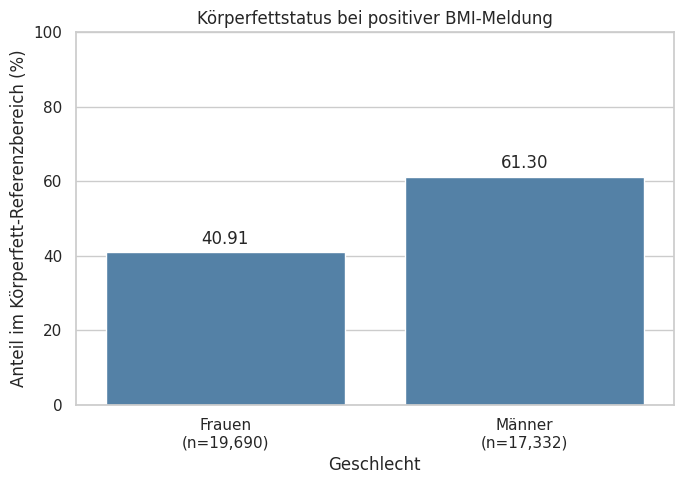

In [36]:
# Daten für die Visualisierung vorbereiten
healthy_bmi_plot = healthy_bmi_summary.reset_index()

healthy_bmi_plot["Geschlecht"] = healthy_bmi_plot["Gender"].map({
    "F": "Frauen",
    "M": "Männer"
})

# Prozentanteile nach Geschlecht darstellen
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=healthy_bmi_plot,
    x="Geschlecht",
    y="Percentage",
    order=["Frauen", "Männer"],
    color="steelblue"
)

# Prozentwerte über den Balken anzeigen
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

# Gruppengrößen an den Kategorien angeben
ax.set_xticks([0, 1])
ax.set_xticklabels([
    f"Frauen\n(n={int(healthy_bmi_summary.loc['F', 'Count']):,})",
    f"Männer\n(n={int(healthy_bmi_summary.loc['M', 'Count']):,})"
])

plt.title("Körperfettstatus bei positiver BMI-Meldung")
plt.xlabel("Geschlecht")
plt.ylabel("Anteil im Körperfett-Referenzbereich (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Interpretation

37.022 Datensätze enthalten die positive BMI-Meldung. Der Textfilter stimmt vollständig mit der Kategorie „Normal weight“ überein. Insgesamt liegen 50,45 % dieser Datensätze laut gespeicherter Spalte `bf_healthy` im Körperfett-Referenzbereich.

Bei Frauen beträgt dieser Anteil 40,91 % (8.055 von 19.690), bei Männern 61,30 % (10.624 von 17.332). Die Differenz beträgt rund 20,39 Prozentpunkte.

Eine positive BMI-Meldung bedeutet in diesem Datensatz somit nicht automatisch, dass auch der geschätzte Körperfettanteil im vorgegebenen Referenzbereich liegt.

Der Körperfettanteil wird aus BMI, Alter und Geschlecht berechnet. Zusätzlich unterscheiden sich die Referenzbereiche nach Alter und Geschlecht. Der beobachtete Unterschied erlaubt daher keine pauschale Aussage darüber, welches Geschlecht gesünder ist. Die zuvor dokumentierten Abweichungen der gespeicherten Statusspalte bleiben berücksichtigt.

---
---


### My Question 2

Among people with a BMI in the normal range, which age and gender groups have the highest percentage of estimated body fat values outside the given reference range?

**Columns:** Age, Gender, bmi_category, bf_healthy

**Constraint:** Cross-categorical

### Warum ist diese Frage interessant?

Meine erste eigene Frage zeigt, dass eine positive BMI-Meldung nicht automatisch bedeutet, dass auch der geschätzte Körperfettanteil im vorgegebenen Referenzbereich liegt. Deshalb untersuche ich nun, in welchen Alters- und Geschlechtsgruppen dies besonders häufig vorkommt.

### Vorgehen

Ich filtere die Datensätze mit der BMI-Kategorie „Normal weight“ und gruppiere sie nach Altersgruppe und Geschlecht.

Für jede Gruppe berechne ich die Anzahl der Datensätze und den Anteil außerhalb des Körperfett-Referenzbereichs (`bf_healthy == False`).

Die Prozentanteile stelle ich als Liniendiagramm mit einer Linie je Geschlecht dar.


In [37]:
# Nur Datensätze mit BMI im Normalbereich auswählen
normal_bmi_data = df.loc[
    df["bmi_category"].eq("Normal weight")
].copy()

# Altersgruppen erstellen
age_order = ["18-29", "30-39", "40-49", "50-59", "60+"]

normal_bmi_data["Age_Group"] = pd.cut(
    normal_bmi_data["Age"],
    bins=[18, 30, 40, 50, 60, np.inf],
    labels=age_order,
    right=False
)

# Gespeicherten Körperfettstatus verwenden
normal_bmi_data["Outside_Range"] = (
    normal_bmi_data["bf_healthy"].eq(False)
)

# Anzahl und Anteil je Alters- und Geschlechtsgruppe berechnen
normal_bmi_summary = (
    normal_bmi_data
    .groupby(["Age_Group", "Gender"], observed=True)
    .agg(
        Count=("Outside_Range", "size"),
        Outside_Count=("Outside_Range", "sum"),
        Proportion=("Outside_Range", "mean")
    )
    .reset_index()
    .sort_values(["Age_Group", "Gender"])
)

# Anteile in Prozent umrechnen
normal_bmi_summary["Percentage"] = (
    normal_bmi_summary["Proportion"] * 100
)

# Vollständigkeit prüfen
print("Datensätze mit BMI im Normalbereich:", len(normal_bmi_data))
print(
    "Datensätze ohne Altersgruppe:",
    normal_bmi_data["Age_Group"].isna().sum()
)
print(
    "Datensätze in der Gruppenauswertung:",
    normal_bmi_summary["Count"].sum()
)

# Ergebnistabelle anzeigen
normal_bmi_table = normal_bmi_summary[
    ["Age_Group", "Gender", "Count", "Outside_Count", "Percentage"]
].copy()

normal_bmi_table["Gender"] = normal_bmi_table["Gender"].map(
    {"F": "Frauen", "M": "Männer"}
)

normal_bmi_table = normal_bmi_table.rename(columns={
    "Age_Group": "Altersgruppe",
    "Gender": "Geschlecht",
    "Count": "Anzahl mit BMI im Normalbereich",
    "Outside_Count": "Anzahl außerhalb des BF-Referenzbereichs",
    "Percentage": "Anteil außerhalb (%)"
})

display(normal_bmi_table.round(2))


Datensätze mit BMI im Normalbereich: 37022
Datensätze ohne Altersgruppe: 0
Datensätze in der Gruppenauswertung: 37022


,Altersgruppe,Geschlecht,Anzahl mit BMI im Normalbereich,Anzahl außerhalb des BF-Referenzbereichs,Anteil außerhalb (%)
0,18-29,Frauen,4138,910,21.99
1,18-29,Männer,4091,49,1.20
2,30-39,Frauen,3324,1519,45.70
3,30-39,Männer,3464,492,14.20
4,40-49,Frauen,3451,1994,57.78
5,40-49,Männer,3169,1271,40.11
6,50-59,Frauen,3239,2268,70.02
7,50-59,Männer,2712,1435,52.91
8,60+,Frauen,5538,4944,89.27
9,60+,Männer,3896,3461,88.83


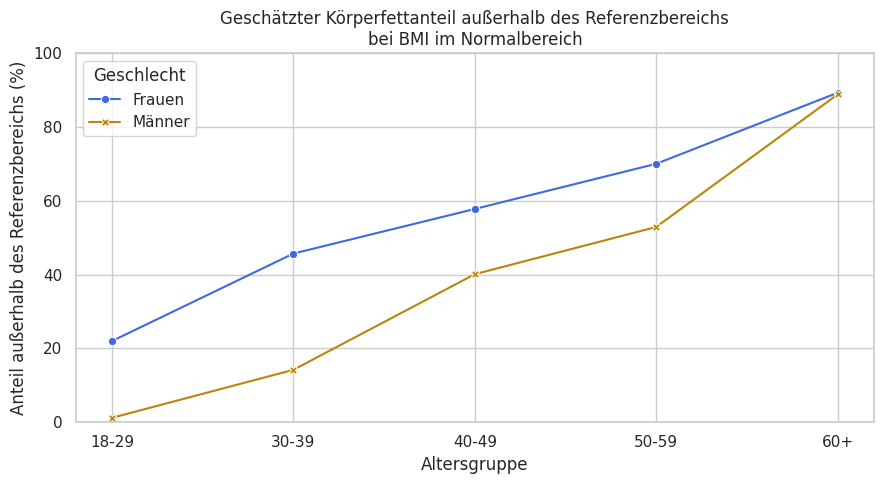

In [38]:
# Daten für das Liniendiagramm vorbereiten
normal_bmi_plot = normal_bmi_summary.copy()

normal_bmi_plot["Geschlecht"] = normal_bmi_plot["Gender"].map(
    {"F": "Frauen", "M": "Männer"}
)

# Prozentanteile nach Altersgruppe und Geschlecht darstellen
plt.figure(figsize=(9, 5))

ax = sns.lineplot(
    data=normal_bmi_plot,
    x="Age_Group",
    y="Percentage",
    hue="Geschlecht",
    style="Geschlecht",
    hue_order=["Frauen", "Männer"],
    style_order=["Frauen", "Männer"],
    markers=True,
    dashes=False,
    palette={"Frauen": "royalblue", "Männer": "darkgoldenrod"},
    estimator=None,
    sort=False
)

plt.title(
    "Geschätzter Körperfettanteil außerhalb des Referenzbereichs\n"
    "bei BMI im Normalbereich"
)
plt.xlabel("Altersgruppe")
plt.ylabel("Anteil außerhalb des Referenzbereichs (%)")
plt.ylim(0, 100)
plt.legend(title="Geschlecht")
plt.tight_layout()
plt.show()

### Interpretation

Auch bei einem BMI im Normalbereich unterscheiden sich die Anteile außerhalb des Körperfett-Referenzbereichs deutlich nach Alter und Geschlecht.

Bei den 18–29-Jährigen liegen 21,99 % der Frauen und 1,20 % der Männer außerhalb des vorgegebenen Referenzbereichs. In den älteren Altersgruppen nehmen die Anteile bei beiden Geschlechtern zu. Die höchsten Anteile zeigen sich in der Altersgruppe ab 60 Jahren.

Ein BMI im Normalbereich bedeutet in diesem Datensatz somit nicht automatisch, dass auch der geschätzte Körperfettanteil im vorgegebenen Referenzbereich liegt.

Dabei gehen Alter und Geschlecht direkt in die Körperfettschätzung ein. Auch die Referenzbereiche unterscheiden sich nach diesen Merkmalen. Die beobachteten Unterschiede sind deshalb teilweise durch die Berechnungs- und Bewertungsregeln vorgegeben und erlauben keine pauschalen Aussagen über den allgemeinen Gesundheitszustand.

Die Auswertung verwendet die gespeicherte Spalte `bf_healthy`; die elf dokumentierten Abweichungen zur Prüffunktion bleiben als Einschränkung bestehen.

Ob die Werte außerhalb des Referenzbereichs darunter oder darüber liegen, untersuche ich in meiner dritten eigenen Frage.

---
---

### My Question 3

Among people with a BMI in the normal range, do estimated body fat values fall more often below or above the given reference ranges, and how large are the deviations?

**Columns:** bmi_category, BF%, Age, Gender, bf_healthy

**Constraint:** Justified

### Warum ist diese Frage interessant?

Meine zweite eigene Frage zeigt, in welchen Alters- und Geschlechtsgruppen der geschätzte Körperfettanteil trotz eines BMI im Normalbereich besonders häufig außerhalb des Referenzbereichs liegt. Offen bleibt jedoch, ob die Werte unterhalb oder oberhalb liegen und wie groß die Abweichungen sind. Deshalb untersuche ich ihre Richtung und Größe. Die Ergebnisse könnten beispielsweise Entwicklern von Fitness-Apps helfen zu entscheiden, welche ergänzenden Hinweise zum geschätzten Körperfettanteil neben einer positiven BMI-Meldung angezeigt werden sollten.

### Vorgehen

Ich wähle die Datensätze mit der BMI-Kategorie „Normal weight“ aus. Für jeden Datensatz bestimme ich anhand von Alter und Geschlecht die untere und obere Grenze aus dem vorgegebenen Dictionary `healthy_bf_ranges`.

Anschließend ordne ich den geschätzten Körperfettanteil einer von drei Kategorien zu: unterhalb, innerhalb oder oberhalb des Referenzbereichs. Werte genau auf den Grenzen zählen als innerhalb.

Für jede Kategorie berechne ich Anzahl und Prozentanteil. Die Prozentanteile beziehen sich auf alle ausgewählten Datensätze mit BMI im Normalbereich.

Für Werte außerhalb berechne ich zusätzlich den medianen Abstand zur jeweiligen Grenze in Prozentpunkten – getrennt für Werte unterhalb und oberhalb.

Die Anteile visualisiere ich in einem Balkendiagramm. Die medianen Abstände zeige ich ergänzend in einer Tabelle.

Da ich die Einordnung anhand der Referenzbereiche neu bestimme, vergleiche ich das Ergebnis zusätzlich mit der gespeicherten Spalte `bf_healthy` und dokumentiere mögliche Unterschiede.


In [ ]:
# Datensätze mit BMI im Normalbereich auswählen
bf_details = df.loc[df["bmi_category"].eq("Normal weight")].copy()

# Altersgruppen passend zum vorgegebenen Dictionary erstellen
bf_details["Age_Group"] = pd.cut(
    bf_details["Age"],
    bins=[18, 30, 40, 50, 60, np.inf],
    labels=["18-29", "30-39", "40-49", "50-59", "60+"],
    right=False
)

# Lage und Abstand zum Referenzbereich bestimmen
def classify_bf_position(row):
    lower, upper = healthy_bf_ranges[row["Age_Group"]][row["Gender"]]
    body_fat = row["BF%"]

    if body_fat < lower:
        return "Unterhalb", lower - body_fat
    elif body_fat > upper:
        return "Oberhalb", body_fat - upper
    else:
        return "Innerhalb", 0.0

bf_details[["BF_Position", "Distance_pp"]] = bf_details.apply(
    classify_bf_position,
    axis=1,
    result_type="expand"
)

# Alle drei Kategorien aufführen, auch bei null Datensätzen
position_order = ["Unterhalb", "Innerhalb", "Oberhalb"]

bf_position_summary = (
    bf_details["BF_Position"]
    .value_counts()
    .reindex(position_order, fill_value=0)
    .rename_axis("Lage")
    .to_frame("Anzahl")
)

# Prozentanteile innerhalb aller ausgewählten Datensätze
bf_position_summary["Anteil (%)"] = (
    bf_position_summary["Anzahl"] / len(bf_details) * 100
)

print("Datensätze mit BMI im Normalbereich:", len(bf_details))
print("\nNeu berechnete Einordnung:")
display(bf_position_summary.round(2))

# Medianer Abstand: nur Werte außerhalb, getrennt nach Richtung
outside_bf = bf_details.loc[
    bf_details["BF_Position"].ne("Innerhalb")
]

distance_summary = (
    outside_bf.groupby("BF_Position")["Distance_pp"]
    .agg(Anzahl="size", Median_Abstand_pp="median")
    .reindex(["Unterhalb", "Oberhalb"])
)

distance_summary["Anzahl"] = (
    distance_summary["Anzahl"].fillna(0).astype(int)
)
distance_summary.index.name = "Lage"

print("\nAbstand zur jeweiligen Referenzgrenze:")
display(
    distance_summary.rename(columns={
        "Median_Abstand_pp": "Medianabstand (Prozentpunkte)"
    }).round(2)
)

# Neue Einordnung mit der gespeicherten Statusspalte vergleichen
within_range_check = bf_details["BF_Position"].eq("Innerhalb")
status_mismatch = within_range_check.ne(bf_details["bf_healthy"])

print(
    "\nAbweichungen von bf_healthy in dieser Auswahl:",
    int(status_mismatch.sum())
)

# Abweichende Datensätze anzeigen
if status_mismatch.any():
    display(bf_details.loc[
        status_mismatch,
        ["Age", "Gender", "BMI", "BF%", "bf_healthy", "BF_Position"]
    ])


In [ ]:
# Prozentanteile visualisieren
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=bf_position_summary.reset_index(),
    x="Lage",
    y="Anteil (%)",
    order=position_order,
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Geschätzter Körperfettanteil bei BMI im Normalbereich")
plt.xlabel("Lage zum vorgegebenen Körperfett-Referenzbereich")
plt.ylabel("Anteil aller Datensätze mit BMI im Normalbereich (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Interpretation

Von den 37.022 Datensätzen mit BMI im Normalbereich liegen 18.679 (50,45 %) innerhalb des vorgegebenen Körperfett-Referenzbereichs. Weitere 18.343 (49,55 %) liegen oberhalb. Kein Wert liegt unterhalb des Referenzbereichs.

Bei den 18.343 Werten oberhalb beträgt der mediane Abstand zur jeweiligen oberen Grenze 2,02 Prozentpunkte. Für Werte unterhalb lässt sich kein Median berechnen, da diese Kategorie keine Datensätze enthält. Deshalb wird dort `NaN` angezeigt.

Die neu berechnete Einordnung stimmt in dieser Auswahl vollständig mit der gespeicherten Spalte `bf_healthy` überein. Es gibt hier keine Abweichungen. Die zuvor dokumentierten elf Abweichungen im gesamten Datensatz bleiben davon unberührt.

Damit lässt sich das Ergebnis meiner ersten eigenen Frage präzisieren: Fast die Hälfte der Datensätze mit positiver BMI-Meldung weist einen geschätzten Körperfettanteil oberhalb des vorgegebenen Referenzbereichs auf.

Der Körperfettanteil wurde aus BMI, Alter und Geschlecht berechnet. Die Ergebnisse hängen deshalb von der Schätzformel und den vorgegebenen Referenzbereichen ab und erlauben keine pauschale Bewertung des allgemeinen Gesundheitszustands.


---
---


## Grenzen der Analyse

Der Körperfettanteil wurde aus BMI, Alter und Geschlecht geschätzt und nicht direkt gemessen. Zusammenhänge mit diesen Merkmalen sind deshalb teilweise durch die Formel vorgegeben. Auch die Referenzbereiche unterscheiden sich nach Alter und Geschlecht.

Die Datenprüfung ergab 96 zusätzliche identische Zeilen, eine ungeklärte Aktivitätskategorie mit nur einem Datensatz, vier geringfügige Abweichungen bei der Körperfettberechnung und elf Abweichungen beim gespeicherten Körperfettstatus. Diese Befunde wurden dokumentiert; die ursprünglichen Werte blieben erhalten. In der untersuchten Teilgruppe mit BMI im Normalbereich stimmen die gespeicherten und neu berechneten Körperfettstatuswerte vollständig überein.

Die Ergebnisse beschreiben Zusammenhänge innerhalb dieses Datensatzes. Sie belegen keine Ursache-Wirkungs-Beziehungen und zeigen keine Veränderungen derselben Personen über die Zeit. Die Ergebnisse beziehen sich auf den vorliegenden Übungsdatensatz. Allgemeine Aussagen über andere Bevölkerungsgruppen lassen sich daraus nicht ableiten.

## Ausblick

Was würde sich ändern, wenn Ärzte und Fitness-Apps neben dem BMI auch einen direkt gemessenen Körperfettanteil berücksichtigen würden? In einer weiterführenden Analyse würde ich untersuchen, ob die beobachteten Unterschiede auch mit solchen Messwerten auftreten.

## Datenquelle und Reproduzierbarkeit

### Datengrundlage

Die Analyse verwendet die für das Abschlussprojekt bereitgestellte Datei `health_data_processed.csv` mit 50.002 Einträgen und elf ursprünglichen Spalten.

Für die Validierung und Auswertung nutze ich die im Starter-Notebook vorgegebenen Hilfsfunktionen und Körperfett-Referenzbereiche. Die Ergebnisse beziehen sich auf den vorliegenden Übungsdatensatz.

### Ausführung des Notebooks

Das Notebook wird in Google Colab ausgeführt. Vor dem Start muss die Datei `health_data_processed.csv` in das Verzeichnis `/content/` hochgeladen werden.

Anschließend sind alle Code-Zellen von oben nach unten auszuführen. Die Hilfsfunktionen müssen vor den Validierungs- und Analysezellen ausgeführt werden.

Die eingelesenen Ausgangsdaten bleiben in `df_raw` erhalten. Für die Analyse wird eine Kopie namens `df` verwendet. Zusätzliche Prüfungen und Auswertungen überschreiben die ursprünglichen Werte nicht.

### Verwendete Umgebung

Die folgende Code-Zelle dokumentiert die Python- und Bibliotheksversionen der aktuellen Ausführung.

In [ ]:
# Python- und Bibliotheksversionen dokumentieren
import sys
import matplotlib

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)

## Gesamtzusammenfassung

In diesem Projekt habe ich sieben vorgegebene und drei eigene Fragen zu einem Gesundheitsdatensatz mit 50.002 Einträgen untersucht. Drei Erkenntnisse stehen im Mittelpunkt: Erstens liegen 49,55 % der Datensätze mit positiver BMI-Meldung oberhalb des vorgegebenen Körperfett-Referenzbereichs. Ihr medianer Abstand zur oberen Grenze beträgt 2,02 Prozentpunkte; unterhalb liegt kein Wert. Zweitens unterscheiden sich die Anteile außerhalb des Referenzbereichs nach Alter und Geschlecht: Bei den 18–29-Jährigen mit BMI im Normalbereich betragen sie 21,99 % bei Frauen und 1,20 % bei Männern. In den älteren Altersgruppen steigen die Anteile bei beiden Geschlechtern. Drittens ist ein höheres Aktivitätslevel in den vier regulären Aktivitätsgruppen mit einem niedrigeren mittleren geschätzten Körperfettanteil verbunden: Dieser beträgt 29,60 % bei „Sedentary“ und 26,51 % bei „Very Active“.

Überraschend war für mich besonders, dass fast die Hälfte der Datensätze mit positiver BMI-Meldung einen geschätzten Körperfettanteil oberhalb des Referenzbereichs aufweist. Allerdings wurde der Körperfettanteil aus BMI, Alter und Geschlecht berechnet und nicht direkt gemessen. Die Ergebnisse hängen deshalb teilweise von der Formel und den vorgegebenen Referenzbereichen ab. Sie beschreiben Zusammenhänge und belegen keine Ursache und Wirkung. Auffälligkeiten der Datenqualität wurden dokumentiert; die ursprünglichen Werte blieben erhalten. Als Nächstes würde ich prüfen, ob sich die beobachteten Muster auch mit direkt gemessenen Körperfettwerten zeigen.